# Imports

In [11]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.utils import image_dataset_from_directory, load_img, img_to_array

import matplotlib.pyplot as plt
from matplotlib import cm

# Config

In [12]:
IMG_SIZE   = (224, 224)      # matches MobileNetV2 pretraining;
CHANNELS   = 3
BATCH_SIZE = 32
VAL_SPLIT  = 0.2

HEAD_EPOCHS      = 25  # base model epochs
FINETUNE_EPOCHS  = 15   # fine tuning epochs
HEAD_LR          = 1e-3 # set small learning rates
FINETUNE_LR      = 1e-5 
UNFREEZE_FROM    = 100 # unfreeze base.layers[100:]

DROPOUT_RATE = 0.3

# Data

In [13]:

train_ds, val_ds = image_dataset_from_directory("Data", labels='inferred', label_mode='binary',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, validation_split=VAL_SPLIT, subset='both', shuffle=True, seed = 19)

CLASS_NAMES = train_ds.class_names
print("Classes:", CLASS_NAMES)

# cache and prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)

Found 187 files belonging to 2 classes.
Using 150 files for training.
Using 37 files for validation.


Classes: ['Elephants', 'Village']


# Model - Need to investigate more

In [14]:
preprocess = keras.applications.mobilenet_v2.preprocess_input

base = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, CHANNELS),
    include_top=False,
    weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, CHANNELS), name="image")

# augmentation on the raw image, auto-disabled at inference
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.RandomContrast(0.1)(x)

x = preprocess(x)                        # scales to [-1, 1] — NOT Rescaling(1./255)

features = base(x, training=False)       # (None, 7, 7, 1280)  <-- keep this handle

x = layers.GlobalAveragePooling2D()(features)
x = layers.Dropout(DROPOUT_RATE)(x)
logits = layers.Dense(1, activation=None, name="logit")(x)   # LINEAR on purpose

classifier = keras.Model(inputs, logits, name="elephant_village")

classifier.compile(
    optimizer=keras.optimizers.Adam(HEAD_LR),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0)])

# Train

## Base - Look into more

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
]

hist_head = classifier.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=callbacks)

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 367ms/step - accuracy: 0.4965 - loss: 0.8169 - val_accuracy: 0.7568 - val_loss: 0.5706 - learning_rate: 0.0010
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step - accuracy: 0.6987 - loss: 0.6079 - val_accuracy: 0.8378 - val_loss: 0.4190 - learning_rate: 0.0010
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 279ms/step - accuracy: 0.8296 - loss: 0.3815 - val_accuracy: 0.8919 - val_loss: 0.3120 - learning_rate: 0.0010
Epoch 4/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 282ms/step - accuracy: 0.8366 - loss: 0.3406 - val_accuracy: 0.9459 - val_loss: 0.2403 - learning_rate: 0.0010
Epoch 5/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 236ms/step - accuracy: 0.8763 - loss: 0.2648 - val_accuracy: 0.9730 - val_loss: 0.1918 - learning_rate: 0.0010
Epoch 6/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step - accuracy: 0.9414 - loss: 0.1949 - val_accuracy: 1.0000 - val_loss: 0.1567 - learning_rate: 0.0010
Epoch 7/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 219ms/step - accuracy: 0.9645 - loss: 0.1728 - val_accuracy: 

## Finetuning - Look into more

In [16]:
base.trainable = True
for layer in base.layers[:UNFREEZE_FROM]:
    layer.trainable = False

for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

classifier.compile(
    optimizer=keras.optimizers.Adam(FINETUNE_LR),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy", threshold=0.0)])

hist_ft = classifier.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS, callbacks=callbacks)

Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - accuracy: 0.9689 - loss: 0.1375 - val_accuracy: 1.0000 - val_loss: 0.1013 - learning_rate: 1.0000e-05
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - accuracy: 0.9921 - loss: 0.1081 - val_accuracy: 1.0000 - val_loss: 0.0673 - learning_rate: 1.0000e-05
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 266ms/step - accuracy: 0.9791 - loss: 0.0808 - val_accuracy: 1.0000 - val_loss: 0.0466 - learning_rate: 1.0000e-05
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 297ms/step - accuracy: 0.9791 - loss: 0.0530 - val_accuracy: 1.0000 - val_loss: 0.0362 - learning_rate: 1.0000e-05
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 284ms/step - accuracy: 1.0000 - loss: 0.0353 - val_accuracy: 1.0000 - val_loss: 0.0306 - learning_rate: 1.0000e-05
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - accuracy: 0.9869 - loss: 0.0342 - val_accuracy: 1.0000 - val_loss: 0.0191 - learning_rate: 1.0000e-05
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 276ms/step - accuracy: 0.9965 - loss:

# Heatmap Utilities - Look into more

/var/folders/cp/wp9c4zrn6xz0wxdm5dqfntvm0000gn/T/ipykernel_28844/4022544755.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored = cm.get_cmap(cmap)(heat)[..., :3]             # (H, W, 3) in 0-1


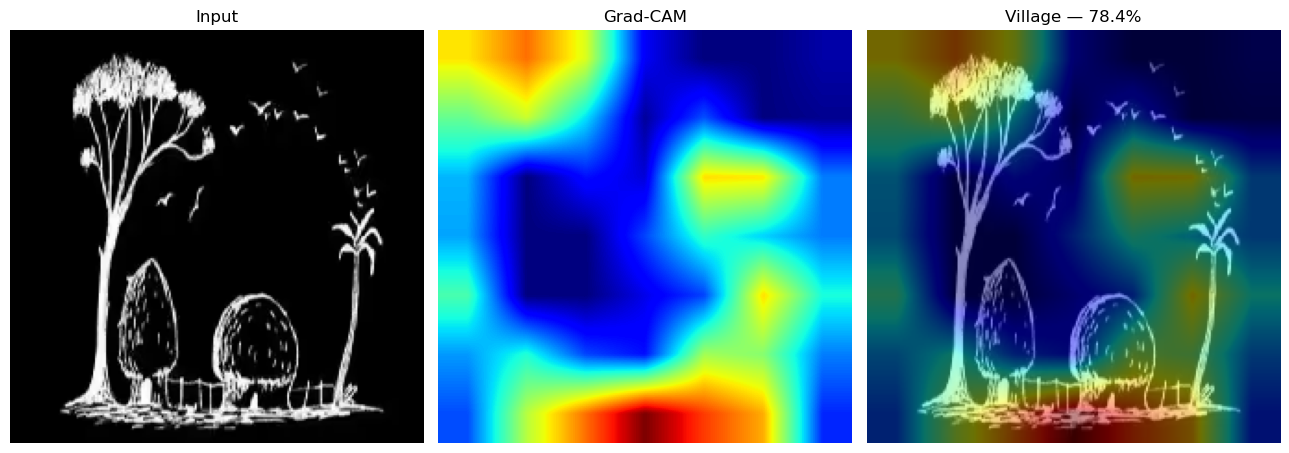

('Village', 0.783958968946478)

In [17]:
grad_model = keras.Model(inputs, [features, logits])

def predict_one(path):
    """Returns (raw_image_uint8, batched_float_array, label, confidence, class_idx)."""
    pil = load_img(path, target_size=IMG_SIZE)
    raw = img_to_array(pil)                       # 0-255 floats, NO scaling
    batch = raw[None, ...]

    logit = float(classifier.predict(batch, verbose=0)[0][0])
    prob  = 1.0 / (1.0 + np.exp(-logit))          # sigmoid applied manually
    idx   = int(prob > 0.5)
    label = CLASS_NAMES[idx]
    conf  = prob if idx else 1.0 - prob
    return raw.astype("uint8"), batch, label, conf, idx


def grad_cam(batch, class_idx):
    """Gradient-weighted class activation map, computed on the LOGIT."""
    batch = tf.cast(batch, tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(batch, training=False)
        tape.watch(conv_out)
        # single-logit binary: positive class = +logit, negative class = -logit
        target = preds[:, 0] if class_idx == 1 else -preds[:, 0]

    grads   = tape.gradient(target, conv_out)              # (1, 7, 7, 1280)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))        # (1280,)
    cam     = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))  # (7, 7)

    cam = cam / (tf.reduce_max(cam) + 1e-8)
    # bilinear upsample to full image resolution
    cam = tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear")
    return tf.squeeze(cam).numpy()


def show_gradcam(path, alpha=0.45, cmap="jet"):
    raw, batch, label, conf, idx = predict_one(path)
    heat = grad_cam(batch, idx)

    colored = cm.get_cmap(cmap)(heat)[..., :3]             # (H, W, 3) in 0-1

    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(raw);                      ax[0].set_title("Input")
    ax[1].imshow(heat, cmap=cmap);          ax[1].set_title("Grad-CAM")
    ax[2].imshow(raw)
    ax[2].imshow(colored, alpha=alpha)      # overlay
    ax[2].set_title(f"{label} — {conf:.1%}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

    return label, conf


show_gradcam("../Test Images/Real Test Invert.png")

# Validation - Look into more

Found 187 files belonging to 2 classes.
Using 150 files for training.
Using 37 files for validation.


/var/folders/cp/wp9c4zrn6xz0wxdm5dqfntvm0000gn/T/ipykernel_28844/3824831200.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  ax.imshow(cm.get_cmap("jet")(heat)[..., :3], alpha=0.4)


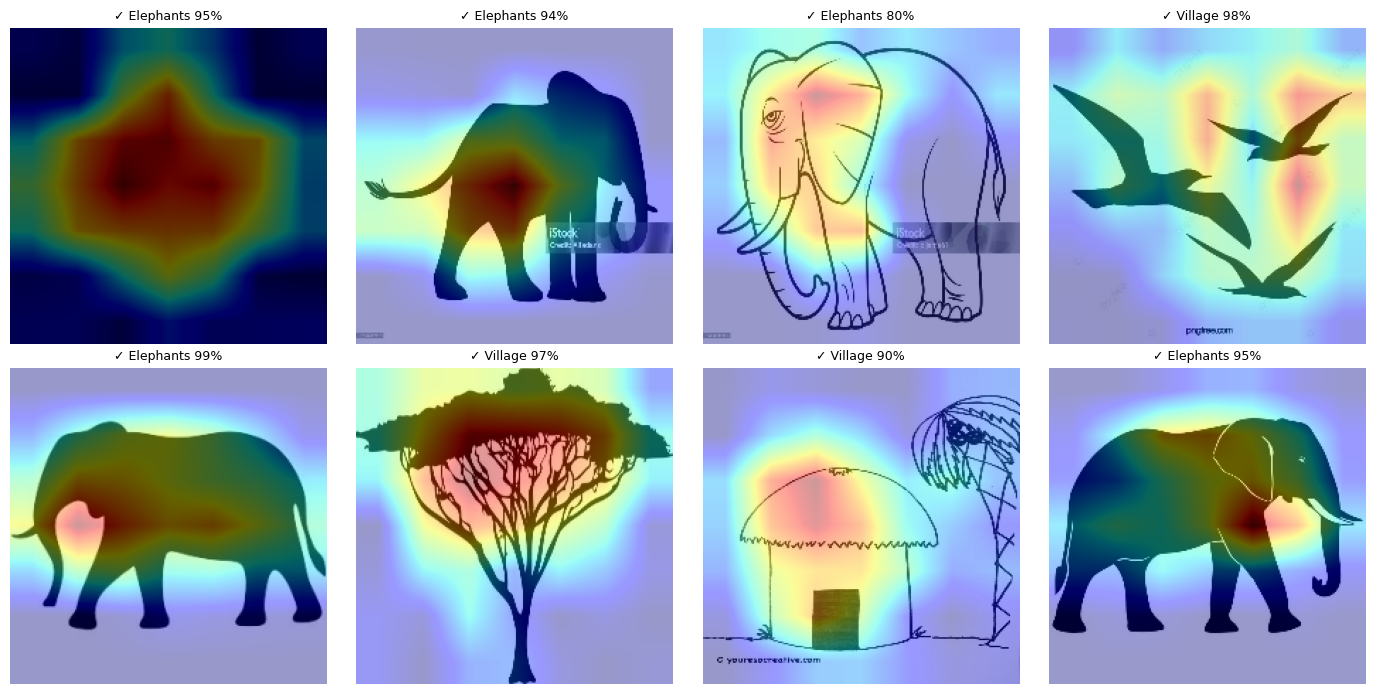

In [18]:
raw_val, _ = image_dataset_from_directory(
    "Data", labels='inferred', label_mode='binary',
    image_size=IMG_SIZE, batch_size=8,
    validation_split=VAL_SPLIT, subset='both',
    shuffle=True, seed=19)

images, labels_true = next(iter(raw_val))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for img, true_lbl, ax in zip(images, labels_true, axes.flat):
    batch = img.numpy()[None, ...]
    logit = float(classifier.predict(batch, verbose=0)[0][0])
    prob  = 1 / (1 + np.exp(-logit))
    idx   = int(prob > 0.5)
    heat  = grad_cam(batch, idx)

    ax.imshow(img.numpy().astype("uint8"))
    ax.imshow(cm.get_cmap("jet")(heat)[..., :3], alpha=0.4)
    ok = "✓" if idx == int(true_lbl[0]) else "✗"
    ax.set_title(f"{ok} {CLASS_NAMES[idx]} {max(prob,1-prob):.0%}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

This model seems pretty good, it acurately classified all test images, and was confused about the water bottle

Classifys the test image as village everytime, even when inverted